# Loan Portfolio Early Warning System

## Objective
To identify loan accounts showing early signs of stress before default using behavioral indicators.

This project focuses on early detection rather than default prediction, enabling proactive risk monitoring.


## Data Understanding

Loading LendingClub dataset and inspecting structure, columns, and basic statistics.

In [ ]:
import pandas as pd


In [ ]:
df = pd.read_csv('loan.csv', nrows=300000)
df.shape

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Columns: 145 entries, id to settlement_term
dtypes: float64(59), int64(51), object(35)
memory usage: 331.9+ MB


In [ ]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,NaN,NaN,2500,2500,2500.0,36 months,13.56,84.92,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,30000,30000,30000.0,60 months,18.94,777.23,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,5000,5000,5000.0,36 months,17.97,180.69,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,4000,4000,4000.0,36 months,18.94,146.51,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,30000,30000,30000.0,60 months,16.14,731.78,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(list(df.columns))

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_i

## Feature Selection

From ~140 columns, a subset of ~15–20 features is selected based on relevance:

- Loan contract features
- Borrower credit profile
- Repayment behavior

Objective:
Keep the dataset lean, interpretable, and free from leakage.

In [ ]:
cols = [
    'loan_amnt','term','int_rate','sub_grade',
    'open_acc','open_acc_6m','revol_util','pub_rec','num_actv_rev_tl','dti',
    'last_pymnt_d','out_prncp','num_tl_30dpd','num_tl_90g_dpd_24m',
    'mths_since_recent_revol_delinq','num_accts_ever_120_pd'
]
df_work=df[cols]

## Exploratory Data Analysis (EDA)

EDA focuses on:
- Missing value analysis
- Distribution checks
- Identifying potential outliers

Only essential analysis is performed to validate assumptions and avoid unnecessary complexity.

In [ ]:
df_work.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 16 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   loan_amnt                       300000 non-null  int64  
 1   term                            300000 non-null  object 
 2   int_rate                        300000 non-null  float64
 3   sub_grade                       300000 non-null  object 
 4   open_acc                        300000 non-null  int64  
 5   open_acc_6m                     300000 non-null  int64  
 6   revol_util                      299664 non-null  float64
 7   pub_rec                         300000 non-null  int64  
 8   num_actv_rev_tl                 300000 non-null  int64  
 9   dti                             299346 non-null  float64
 10  last_pymnt_d                    299648 non-null  object 
 11  out_prncp                       300000 non-null  float64
 12  num_tl_30dpd    

In [ ]:
df_work.isnull().sum()

loan_amnt                              0
term                                   0
int_rate                               0
sub_grade                              0
open_acc                               0
open_acc_6m                            0
revol_util                           336
pub_rec                                0
num_actv_rev_tl                        0
dti                                  654
last_pymnt_d                         352
out_prncp                              0
num_tl_30dpd                           0
num_tl_90g_dpd_24m                     0
mths_since_recent_revol_delinq    213650
num_accts_ever_120_pd                  0
dtype: int64

In [ ]:
df_work.describe()

,loan_amnt,int_rate,open_acc,open_acc_6m,revol_util,pub_rec,num_actv_rev_tl,dti,out_prncp,num_tl_30dpd,num_tl_90g_dpd_24m,mths_since_recent_revol_delinq,num_accts_ever_120_pd
count,300000.000000,300000.000000,300000.000000,300000.000000,299664.000000,300000.000000,300000.000000,299346.000000,300000.000000,300000.0,300000.000000,86350.000000,300000.000000
mean,16014.054750,12.887108,11.525837,0.896020,44.191665,0.123453,5.405640,19.751158,13726.983134,0.0,0.059720,37.883173,0.470740
std,10126.044723,5.213248,5.953563,1.116449,24.773922,0.335042,3.435665,20.103078,9664.905819,0.0,0.425724,21.992907,1.377199
min,1000.000000,5.310000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,1.000000,0.000000
25%,8000.000000,8.460000,7.000000,0.000000,24.700000,0.000000,3.000000,11.570000,6385.052500,0.0,0.000000,20.000000,0.000000
50%,14000.000000,11.800000,10.000000,1.000000,42.400000,0.000000,5.000000,17.790000,11428.185000,0.0,0.000000,35.000000,0.000000
75%,21950.000000,16.140000,14.000000,1.000000,62.500000,0.000000,7.000000,25.070000,19271.965000,0.0,0.000000,53.000000,0.000000
max,40000.000000,30.990000,101.000000,13.000000,183.800000,6.000000,59.000000,999.000000,40000.000000,0.0,58.000000,190.000000,58.000000


## Target Definition (Early Stress)

A binary target variable is created to identify early signs of stress.

Early Stress = 1 if ANY of the following:
- 30+ DPD accounts (this column is zero throughout the sample, so it has no effect)
- 90+ DPD in last 24 months
- 120+ DPD historically
- recent revolving delinquency (≤ 6 months)

Else → 0

This approach avoids lagging default labels and enables early detection.

In [ ]:
df_work['early_stress']=(
    (df_work['num_tl_30dpd']>0) |
    (df_work['num_tl_90g_dpd_24m']>0) |
    (df_work['num_accts_ever_120_pd']>0) |
    (df_work['mths_since_recent_revol_delinq'].le(6))
).astype(int)

df_work['early_stress'].value_counts(normalize=True)

C:\Users\bansh\AppData\Local\Temp\ipykernel_13016\2089711864.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_work['early_stress']=(


early_stress
0    0.774787
1    0.225213
Name: proportion, dtype: float64

In [ ]:
cols_to_check=[
    'loan_amnt',
    'int_rate',
    'open_acc_6m',
    'revol_util',
    'dti',
    'num_tl_30dpd',
    'num_tl_90g_dpd_24m'
]

df_work.groupby('early_stress')[cols_to_check].mean()

,loan_amnt,int_rate,open_acc_6m,revol_util,dti,num_tl_30dpd,num_tl_90g_dpd_24m
early_stress,,,,,,,
0,16379.871233,12.573696,0.856201,44.279234,20.114902,0.0,0.000000
1,14755.560284,13.965319,1.033006,43.890318,18.501046,0.0,0.265171


<Axes: title={'center': 'int_rate'}, xlabel='early_stress'>

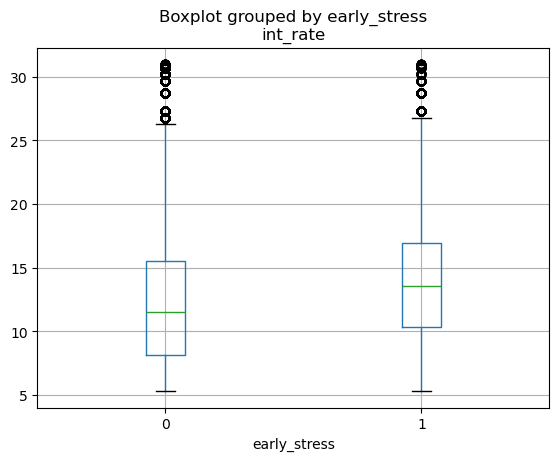

In [ ]:
df_work.boxplot(column='int_rate', by='early_stress')

## Feature Engineering

Key transformations:

### DTI Handling
- DTI = 999 indicates missing income
- Created `dti_missing` flag
- Replaced 999 with NaN to avoid distortion

### Delinquency Signals
- Converted sparse delinquency variables into binary flags
- Missing values interpreted as "no delinquency"

### Categorical Encoding
- `term` converted to numeric using regex
- `sub_grade` encoded ordinally to preserve risk order

In [ ]:
df_fe= df_work.copy()

In [ ]:
df_fe['dti_missing']=(df_fe['dti']==999).astype(int)
df_fe.loc[df_fe['dti']==999,'dti']=None


In [ ]:
df_fe['recent_revol_delinq_6m']= (df_fe['mths_since_recent_revol_delinq'].le(6)).fillna(0).astype(int)
df_fe['ever_120dpd']=(df_fe['num_accts_ever_120_pd']>0).astype(int)
df_fe['any_30dpd']=(df_fe['num_tl_30dpd']>0).astype(int)
df_fe['any_90dpd_24m']=(df_fe['num_tl_90g_dpd_24m']>0).astype(int)

In [ ]:
df_fe['term_num']= df_fe['term'].str.extract('(\d+)').astype(int)
subgrade_map={f'{g}{i}':(ord(g)-64)*10+i for g in 'ABCDEFG' for i in range(1,6)}
df_fe['sub_grade_ord']=df_fe['sub_grade'].map(subgrade_map)

In [ ]:
final_features=[
    'loan_amnt', 'term_num', 'int_rate', 'sub_grade_ord',
    'open_acc', 'open_acc_6m', 'revol_util', 'pub_rec', 'num_actv_rev_tl',
    'dti', 'dti_missing', 'out_prncp'
]

x=df_fe[final_features]
y=df_fe['early_stress']

In [ ]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 12 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   loan_amnt        300000 non-null  int64  
 1   term_num         300000 non-null  int32  
 2   int_rate         300000 non-null  float64
 3   sub_grade_ord    300000 non-null  int64  
 4   open_acc         300000 non-null  int64  
 5   open_acc_6m      300000 non-null  int64  
 6   revol_util       299664 non-null  float64
 7   pub_rec          300000 non-null  int64  
 8   num_actv_rev_tl  300000 non-null  int64  
 9   dti              299306 non-null  float64
 10  dti_missing      300000 non-null  int32  
 11  out_prncp        300000 non-null  float64
dtypes: float64(4), int32(2), int64(6)
memory usage: 25.2 MB


## Data Leakage Handling

Initial model showed perfect performance (ROC-AUC = 1.0), indicating leakage.

Root cause:
Features used to define the target were also included in the model.

Fix:
Removed all target-derived features from model inputs.

Rule:
Features used to create the target must not be used for prediction.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

In [ ]:
import numpy as np

# After train-test split
print("NaN in x_train:", np.isnan(x_train.values).any())
print("NaN in x_test :", np.isnan(x_test.values).any())

NaN in x_train: True
NaN in x_test : True


In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

x_train_imp = imputer.fit_transform(x_train)
x_test_imp  = imputer.transform(x_test)

In [ ]:
print("NaN after imputation (train):", np.isnan(x_train_imp).any())
print("NaN after imputation (test) :", np.isnan(x_test_imp).any())

NaN after imputation (train): False
NaN after imputation (test) : False


## Modeling

Model used: Logistic Regression

Reasons:
- Interpretable
- Suitable for risk teams
- Easy to explain

Handling steps:
- Missing values imputed using median
- Features scaled using StandardScaler
- Class imbalance handled using class_weight='balanced'

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_imp)
x_test_scaled  = scaler.transform(x_test_imp)

logit = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

logit.fit(x_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

In [ ]:
y_pred_prob= logit.predict_proba(x_test_scaled)[:,1]
y_pred=(y_pred_prob >= 0.5).astype(int)

## Model Evaluation

Evaluation metrics:
- ROC-AUC
- Confusion matrix
- Classification report

Focus:
Recall is prioritized over accuracy since missing risky accounts is more costly than false alarms.

In [ ]:
print('ROC-AUC:', roc_auc_score(y_test, y_pred_prob))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

ROC-AUC: 0.636530900831082
[[35356 22753]
 [ 6890 10001]]
              precision    recall  f1-score   support

           0       0.84      0.61      0.70     58109
           1       0.31      0.59      0.40     16891

    accuracy                           0.60     75000
   macro avg       0.57      0.60      0.55     75000
weighted avg       0.72      0.60      0.64     75000



In [ ]:
import pandas as pd

In [ ]:
coef_df=pd.DataFrame({
    'features':x.columns,
    'coef':logit.coef_[0]
}).sort_values('coef', ascending=False)

coef_df



,features,coef
3,sub_grade_ord,0.837154
4,open_acc,0.111079
5,open_acc_6m,0.106433
11,out_prncp,0.070546
10,dti_missing,-0.000077
6,revol_util,-0.036118
8,num_actv_rev_tl,-0.078177
1,term_num,-0.134877
0,loan_amnt,-0.181545
9,dti,-0.198552


## Threshold Tuning

Default threshold = 0.5

Adjusted threshold = 0.4

Reason:
Improves recall significantly, allowing better detection of early stress cases.

Trade-off:
- Higher false positives (acceptable)
- Lower false negatives (critical improvement)

In [ ]:
for t in[0.40, 0.50]:
    y_pred_t=(y_pred_prob >= t).astype(int)
    print(f'\nThreshold = {t}')
    print(confusion_matrix(y_test, y_pred_t))
    print(classification_report(y_test, y_pred_t))


Threshold = 0.4
[[14320 43789]
 [ 1894 14997]]
              precision    recall  f1-score   support

           0       0.88      0.25      0.39     58109
           1       0.26      0.89      0.40     16891

    accuracy                           0.39     75000
   macro avg       0.57      0.57      0.39     75000
weighted avg       0.74      0.39      0.39     75000


Threshold = 0.5
[[35356 22753]
 [ 6890 10001]]
              precision    recall  f1-score   support

           0       0.84      0.61      0.70     58109
           1       0.31      0.59      0.40     16891

    accuracy                           0.60     75000
   macro avg       0.57      0.60      0.55     75000
weighted avg       0.72      0.60      0.64     75000



## Final Insights

- Model achieved ~0.64 ROC-AUC (realistic, non-leaky)
- Recall improved significantly with threshold tuning (from ~59% to ~89%), enabling better detection of early stress cases.
- Threshold 0.4 flags most accounts (about 78%), so this is a baseline monitoring model, not production-ready
- Sub-grade and recent credit activity are strong risk indicators
- Credit risk is multi-factor and not driven by a single variable

Conclusion:
This model is suitable as an early warning / monitoring tool, not a default prediction model.